# Sagert EOS: Computational Implementation

This notebook develops the computational implementation of the physics explored in `sagert_eos_physics.ipynb`, following Sagert et al., *Compact Stars for Undergraduates*.

## Aim

To translate the physical equations developed in the accompanying physics notebook into Python, building and testing the numerical methods required to model compact stars.


### Numerical verification

The numerical calculations were checked during development against the corresponding analytical expressions and expected limiting behaviour. Temporary diagnostic checks were removed where they no longer contributed to the clarity of the notebook.

In [343]:
from scipy import constants  
import numpy as np           
from scipy.optimize import brentq      

In [344]:
# Physical constants in SI units
hbar = constants.hbar                   # Reduced Planck constant, J s
m_N = constants.m_n                      # Neutron mass used as representative nucleon mass, kg
pi = constants.pi                          # i mean, it's pi

In [345]:
# Sagert Eq. (15): Fermi momentum as a function of mass density
# rho: mass density, kg/m^3
# A: nucleon number
# Z: proton number
# Returns k_F in kg m/s

def fermi_momentum(rho, A, Z):
    term = ((3*pi**2*rho*Z)/(m_N*A))
    return hbar*(term)**(1/3)

In [346]:
fermi_momentum(1e6, 12, 6)              

2.180425027556546e-23

In [347]:
fermi_momentum(8e9, 12, 6)             

4.360850055113092e-22

In [348]:
m_e = constants.m_e                  # Electron mass, kg
c = constants.c                      # Speed of light, m/s

In [349]:
# Sagert Eq. (19): characteristic electron energy density
# epsilon_0 has units of J/m^3

epsilon_0 = ((m_e**4*c**5)/(pi**2*hbar**3))

In [350]:
epsilon_0                  

1.4405597245585048e+23

In [351]:
# Sagert Eq. (20): Relativity parameter for the degenerate electrons
# k_F: Fermi momentum, kg m/s
# Returns x, a dimensionless quantity
# x << 1: non relativistic
# x ~ 1: transition between regimes
# x >> 1: relativistic

def relativity_parameter(k_F):
    return k_F/(m_e*c)

In [352]:
# carbon 12 at a mass density of 10^9 kg/m^3
# rho is mass density 
# A is number of nucleons in the nucleus
# z is number of protons in the nucleus

rho = 1e9
A = 12
Z = 6

k_F = fermi_momentum(rho, A, Z)

In [353]:
relativity_parameter(k_F)

0.7984200965698063

In [354]:
# Sagert Eq. (18): Electron energy density of the degenerate electron gas
# k_F: Fermi momentum, kg m/s
# Returns electron energy density in J/m^3

def electron_energy_density(k_F):
    x = relativity_parameter(k_F)
    return (epsilon_0/8)*((2*x**3 + x)*np.sqrt(1 + x**2) - np.arcsinh(x))


In [355]:
electron_energy_density(k_F)

2.8682566560743896e+22

In [356]:
# Sagert Eq. (16): Total energy density of the white dwarf matter
# rho: mass density, kg/m^3
# k_F: Fermi momentum, kg m/s
# Returns total energy density in J/m^3

def total_energy_density(rho, k_F):
    return rho*c**2 + electron_energy_density(k_F)

In [357]:
total_energy_density(rho, k_F)

8.99042004402425e+25

In [358]:
# Sagert Eq. (22): Electron degeneracy pressure
# k_F: Fermi momentum, kg m/s
# Returns pressure in Pa

def electron_pressure(k_F):
    x = relativity_parameter(k_F)
    return (epsilon_0/24)*((2*x**3 -3*x)*np.sqrt(1 + x**2) + 3*np.arcsinh(x))

In [359]:
electron_pressure(k_F)

2.5920278311147914e+21

In [360]:
def non_relativistic_pressure(epsilon, A, Z):
    return (hbar**2)/(15*pi**2*m_e)*((3*pi**2*Z)/(m_N*c**2*A))**(5/3)*epsilon**(5/3)

In [361]:
# Sagert approximation for the limiting equations of state
epsilon = rho*c**2

In [362]:
non_relativistic_pressure(epsilon, A, Z)

3.115998991399323e+21

In [363]:
def relativistic_pressure(epsilon, A, Z):
    return (hbar*c)/(12*pi**2)*((3*pi**2*Z)/(m_N*c**2*A))**(4/3)*epsilon**(4/3)

In [364]:
relativistic_pressure(epsilon, A, Z)

4.878382640896561e+21

In [365]:
def polytropic_index(gamma):
    return 1/(gamma-1)

In [366]:
polytropic_index(5/3)

1.4999999999999998

In [367]:
polytropic_index(4/3)

3.000000000000001

In [368]:
# Sagert Eq. (7): Rate of change of enclosed mass
# r: radius in metres
# epsilon: energy density in J/m^3
# Returns dm/dr in kg/m

def mass_gradient(r, epsilon):
    return 4*pi*r**2*epsilon/c**2

In [369]:
G = constants.G

# Sagert Eq. (8): Rate of change of pressure
# r: radius in metres
# epsilon: energy density in J/m^3
# m: enclosed mass in kg
# Returns dp/dr in Pa/m

def pressure_gradient(r, epsilon, m):
    return -G*epsilon*m/(c**2*r**2)

In [370]:
# Inverse polytropic EOS: energy density from pressure
# p: pressure in Pa
# K: polytropic constant
# gamma: polytropic exponent
# Returns energy density in J/m^3

def polytropic_energy_density(p, K, gamma):
    return (p/K)**(1/gamma)


In [371]:
def stellar_structure(r, y, K, gamma):
    m, p = y

    epsilon = polytropic_energy_density(max(p, 0.0), K, gamma)

    dm_dr = mass_gradient(r, epsilon)
    dp_dr = pressure_gradient(r, epsilon, m)

    return [dm_dr, dp_dr]


In [372]:
# Initial conditions near the stellar centre
# p_c: central pressure in Pa
# r0: starting radius in metres

def initial_conditions(p_c, r0, K, gamma):
    epsilon_c = polytropic_energy_density(p_c, K, gamma)

    m0 = (4*pi*r0**3*epsilon_c)/(3*c**2)

    return [m0, p_c]


In [373]:
A = 12
Z = 6
gamma = 5/3

rho_c = 1e9
epsilon_c = rho_c*c**2

# Central pressure from our existing EOS
p_c = non_relativistic_pressure(epsilon_c, A, Z)

# Polytropic constant for this EOS
K = p_c / epsilon_c**gamma

# Begin one metre from the stellar centre
r0 = 1.0

# Initial enclosed mass and pressure
y0 = initial_conditions(p_c, r0, K, gamma)

print("Central pressure:", p_c, "Pa")
print("Initial state:", y0)

Central pressure: 3.115998991399323e+21 Pa
Initial state: [4188790204.786393, 3.115998991399323e+21]


In [374]:
# Stop integration when pressure reaches zero

def stellar_surface(r, y, K, gamma):
    m, p = y
    return p

stellar_surface.terminal = True
stellar_surface.direction = -1

In [375]:
from scipy.integrate import solve_ivp

# Integrate the Newtonian stellar structure equations
solution = solve_ivp(
    stellar_structure,
    (r0, 5e7),
    y0,
    args=(K, gamma),
    events=stellar_surface,
    rtol=1e-8,
    atol=[1e15, 1e10]
)

print("Solver status:", solution.message)
print("Surface detected:", len(solution.t_events[0]) > 0)


Solver status: A termination event occurred.
Surface detected: True


In [376]:
R = solution.t_events[0][0]
M = solution.y_events[0][0][0]

M_sun = constants.M_sun if hasattr(constants, "M_sun") else 1.98847e30

print("Stellar radius:", R/1000, "km")
print("Stellar mass:", M/M_sun, "solar masses")


Stellar radius: 11135.953836181094 km
Stellar mass: 0.4855031786028141 solar masses


In [377]:
# Check numerical convergence using tighter tolerances

solution_fine = solve_ivp(
    stellar_structure,
    (r0, 5e7),
    y0,
    args=(K, gamma),
    events=stellar_surface,
    rtol=1e-10,
    atol=[1e12, 1e7]
)

if solution_fine.success and len(solution_fine.t_events[0]) > 0:
    R_fine = solution_fine.t_events[0][0]
    M_fine = solution_fine.y_events[0][0][0]

    print("Radius difference (%):", abs(R_fine-R)/R*100)
    print("Mass difference (%):", abs(M_fine-M)/M*100)
else:
    print("Convergence test failed:", solution_fine.message)


Radius difference (%): 0.006256948116842676
Mass difference (%): 2.1567063265241264e-07


In [378]:
# Calculate the mass and radius of a Newtonian polytropic star
# rho_c: central mass density in kg/m^3
# K: polytropic EOS constant
# gamma: polytropic exponent
# Returns radius in metres and mass in kg

def solve_star(rho_c, K, gamma):
    epsilon_c = rho_c*c**2
    p_c = K*epsilon_c**gamma

    r0 = 1.0
    y0 = initial_conditions(p_c, r0, K, gamma)

    solution = solve_ivp(
        stellar_structure,
        (r0, 5e7),
        y0,
        args=(K, gamma),
        events=stellar_surface,
        rtol=1e-8,
          atol=[1e15, 1e10]
    )

    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError("Stellar surface was not found")

    R = solution.t_events[0][0]
    M = solution.y_events[0][0][0]

    return R, M


In [379]:
R_test, M_test = solve_star(1e9, K, 5/3)

print("Radius:", R_test/1000, "km")
print("Mass:", M_test/M_sun, "solar masses")


Radius: 11135.953836181094 km
Mass: 0.4855031786028141 solar masses


In [380]:
# Calculate a sequence of white dwarf models

central_densities = np.logspace(7, 10, 10)

radii = []
masses = []

for rho_c in central_densities:
    R, M = solve_star(rho_c, K, gamma)

    radii.append(R / 1000)
    masses.append(M / M_sun)

print("Calculated", len(masses), "stellar models")

Calculated 10 stellar models


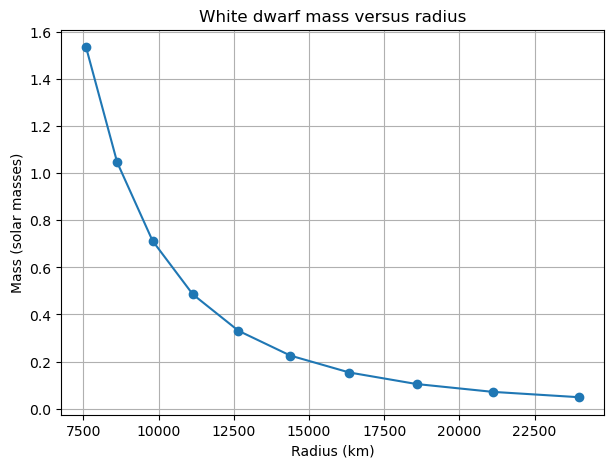

In [381]:
import matplotlib.pyplot as plt

# Mass versus radius for Newtonian polytropic white dwarfs

plt.figure(figsize=(7, 5))

plt.plot(radii, masses, marker="o")

plt.xlabel("Radius (km)")
plt.ylabel("Mass (solar masses)")
plt.title("White dwarf mass versus radius")

plt.grid(True)
plt.show()


In [382]:
mass_radius_products = []
for M, R in zip(masses, radii):
    mass_radius_products.append(M * R**3)

In [383]:
mass_radius_products

[669854963946.7545,
 670657311048.9906,
 670260399522.6011,
 670204536562.0084,
 670137509459.249,
 670166279919.1392,
 670462270319.1823,
 670405812039.4967,
 670311107979.9692,
 670345454786.127]

In [384]:
min(mass_radius_products)

669854963946.7545

In [385]:
max(mass_radius_products)

670657311048.9906

In [386]:
# Verify Sagert's n=3/2 polytropic scaling: M*R^3 should remain constant.

(max(mass_radius_products) - min(mass_radius_products))/(min(mass_radius_products))*100

variation = (max(mass_radius_products) - min(mass_radius_products))/(min(mass_radius_products))*100
if variation < 1:
    print ("scaling test passed (%)", variation)
else:
    print ("scaling test failed", variation)

scaling test passed (%) 0.11977922765678885


In [387]:
def pressure_difference(k_F, p_target):
    return electron_pressure(k_F) - p_target

In [396]:
def energy_density_from_pressure(p_target):
    if p_target <= 0:
        return 0.0
    k_low = 0.0
    k_high = m_e*c
    while electron_pressure(k_high) < p_target:
            k_high = k_high*2
    k_F = brentq(pressure_difference, k_low, k_high, args=(p_target,), xtol=1e-30)
    rho = (m_N * A / (3 * pi**2 * Z)) * (k_F / hbar)**3
    return total_energy_density(rho, k_F)


In [397]:
k_test = fermi_momentum(1e9, 12, 6)
p_test = electron_pressure(k_test)

epsilon_expected = total_energy_density(1e9, k_test)
epsilon_calculated = energy_density_from_pressure(p_test)

print("Expected energy density:", epsilon_expected)
print("Recovered energy density:", epsilon_calculated)
print("Percentage difference:", abs(epsilon_calculated - epsilon_expected) / epsilon_expected * 100)

Expected energy density: 8.99042004402425e+25
Recovered energy density: 8.990420044021823e+25
Percentage difference: 2.7001135695686657e-11


In [398]:
# Newtonian stellar structure using the full electron EOS

def stellar_structure_full(r, y):
    m, p = y

    epsilon = energy_density_from_pressure(p)

    dm_dr = mass_gradient(r, epsilon)
    dp_dr = pressure_gradient(r, epsilon, m)

    return [dm_dr, dp_dr]

In [399]:
def stellar_surface_full(r, y):
    m, p = y
    return p

stellar_surface_full.terminal = True
stellar_surface_full.direction = -1

In [400]:
# Initial conditions for the full electron EOS white dwarf

A = 12
Z = 6

# Central mass density in kg/m^3
rho_c = 1e9

# Starting radius in metres
r0 = 1.0

# Calculate central Fermi momentum and pressure
k_F_c = fermi_momentum(rho_c, A, Z)
p_c = electron_pressure(k_F_c)

# Calculate central total energy density
epsilon_c = total_energy_density(rho_c, k_F_c)

# Approximate enclosed mass inside the starting radius
m0 = (4 * pi * r0**3 * epsilon_c) / (3 * c**2)

# Initial mass and pressure for the numerical solver
y0_full = [m0, p_c]

In [401]:
# Integrate the Newtonian white dwarf using the full electron EOS

solution_full = solve_ivp(
    stellar_structure_full,
    (r0, 5e7),
    y0_full,
    events=stellar_surface_full,
    rtol=1e-8,
    atol=[1e15, 1e10]
)

print("Solver status:", solution_full.message)
print("Surface detected:", len(solution_full.t_events[0]) > 0)

Solver status: A termination event occurred.
Surface detected: True


In [402]:
# Extract mass and radius of the full EOS white dwarf

R_full = solution_full.t_events[0][0]
M_full = solution_full.y_events[0][0][0]

print("Full EOS radius:", R_full / 1000, "km")
print("Full EOS mass:", M_full / M_sun, "solar masses")

Full EOS radius: 10877.420823924116 km
Full EOS mass: 0.39240899801835394 solar masses


In [403]:
# Check numerical convergence of the full EOS white dwarf

solution_full_fine = solve_ivp(
    stellar_structure_full,
    (r0, 5e7),
    y0_full,
    events=stellar_surface_full,
    rtol=1e-10,
    atol=[1e12, 1e7]
)

if solution_full_fine.success and len(solution_full_fine.t_events[0]) > 0:
    R_full_fine = solution_full_fine.t_events[0][0]
    M_full_fine = solution_full_fine.y_events[0][0][0]

    print("Radius difference (%):", abs(R_full_fine - R_full) / R_full * 100)
    print("Mass difference (%):", abs(M_full_fine - M_full) / M_full * 100)
else:
    print("Convergence check failed:", solution_full_fine.message)

Radius difference (%): 0.005403181547700543
Mass difference (%): 2.5857628666900055e-07


In [405]:
# Calculate the mass and radius of a white dwarf using the full electron EOS

def solve_star_full(rho_c):
    k_F_c = fermi_momentum(rho_c, A, Z)
    p_c = electron_pressure(k_F_c)
    epsilon_c = total_energy_density(rho_c, k_F_c)

    r0 = 1.0
    m0 = (4 * pi * r0**3 * epsilon_c) / (3 * c**2)
    y0 = [m0, p_c]

    solution = solve_ivp(
        stellar_structure_full,
        (r0, 5e7),
        y0,
        events=stellar_surface_full,
        rtol=1e-8,
        atol=[1e15, 1e10]
    )

    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError("Full EOS stellar surface was not found")

    R = solution.t_events[0][0]
    M = solution.y_events[0][0][0]

    return R, M

In [414]:
# Calculate a sequence of white dwarfs using the full electron EOS

central_densities_full = np.logspace(7, 10, 10)

radii_full = []
masses_full = []

for rho_c in central_densities_full:
    R, M = solve_star_full(rho_c)

    radii_full.append(R / 1000)
    masses_full.append(M / M_sun)

print("Calculated", len(masses_full), "full EOS stellar models")

Calculated 10 full EOS stellar models


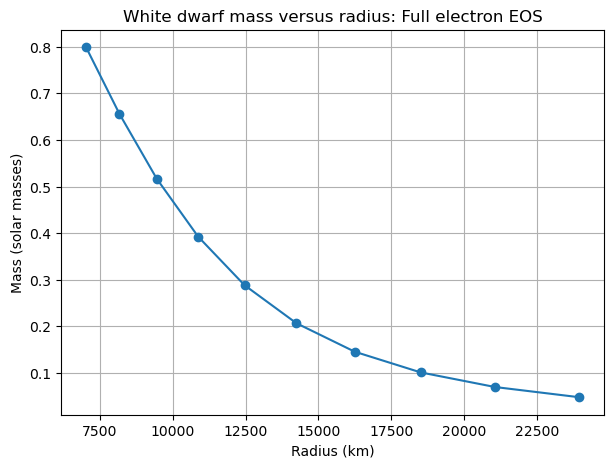

In [415]:
plt.figure(figsize=(7, 5))

plt.plot(radii_full, masses_full, marker="o")

plt.xlabel("Radius (km)")
plt.ylabel("Mass (solar masses)")
plt.title("White dwarf mass versus radius: Full electron EOS")

plt.grid(True)
plt.show()

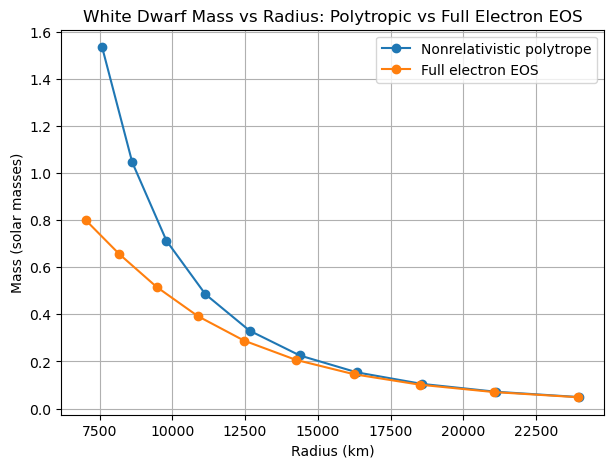

In [416]:
plt.figure(figsize=(7, 5))

plt.xlabel("Radius (km)")
plt.ylabel("Mass (solar masses)")
plt.title("White Dwarf Mass vs Radius: Polytropic vs Full Electron EOS")
plt.plot(radii, masses, marker="o", label="Nonrelativistic polytrope")
plt.plot(radii_full, masses_full, marker="o", label="Full electron EOS")

plt.legend()

plt.grid(True)
plt.show()